# Steam Game Thumbnail Generation with a GAN

Every Steam game has a header image: a 460 × 215 banner with a logo, a character and a colour mood that tries to make you click. Can a neural network learn what a Steam thumbnail looks like, well enough to invent new ones? Here I download thousands of real headers and train a **GAN**: two networks competing, one forges thumbnails and one detects forgeries (DCGAN layout with the stabilising tricks of SN-GAN). Then I ask honest questions: how close are the fakes to real thumbnails (FID), did the network just copy its training images, and what does its "imagination space" look like?

**Data** → [Kaggle dataset nikdavis/steam-store-games](https://www.kaggle.com/datasets/nikdavis/steam-store-games) · header image URLs in `steam_media_data.csv` · images downloaded from Steam's CDN (needs Internet on)

<!-- objective -->
## Aim and objectives

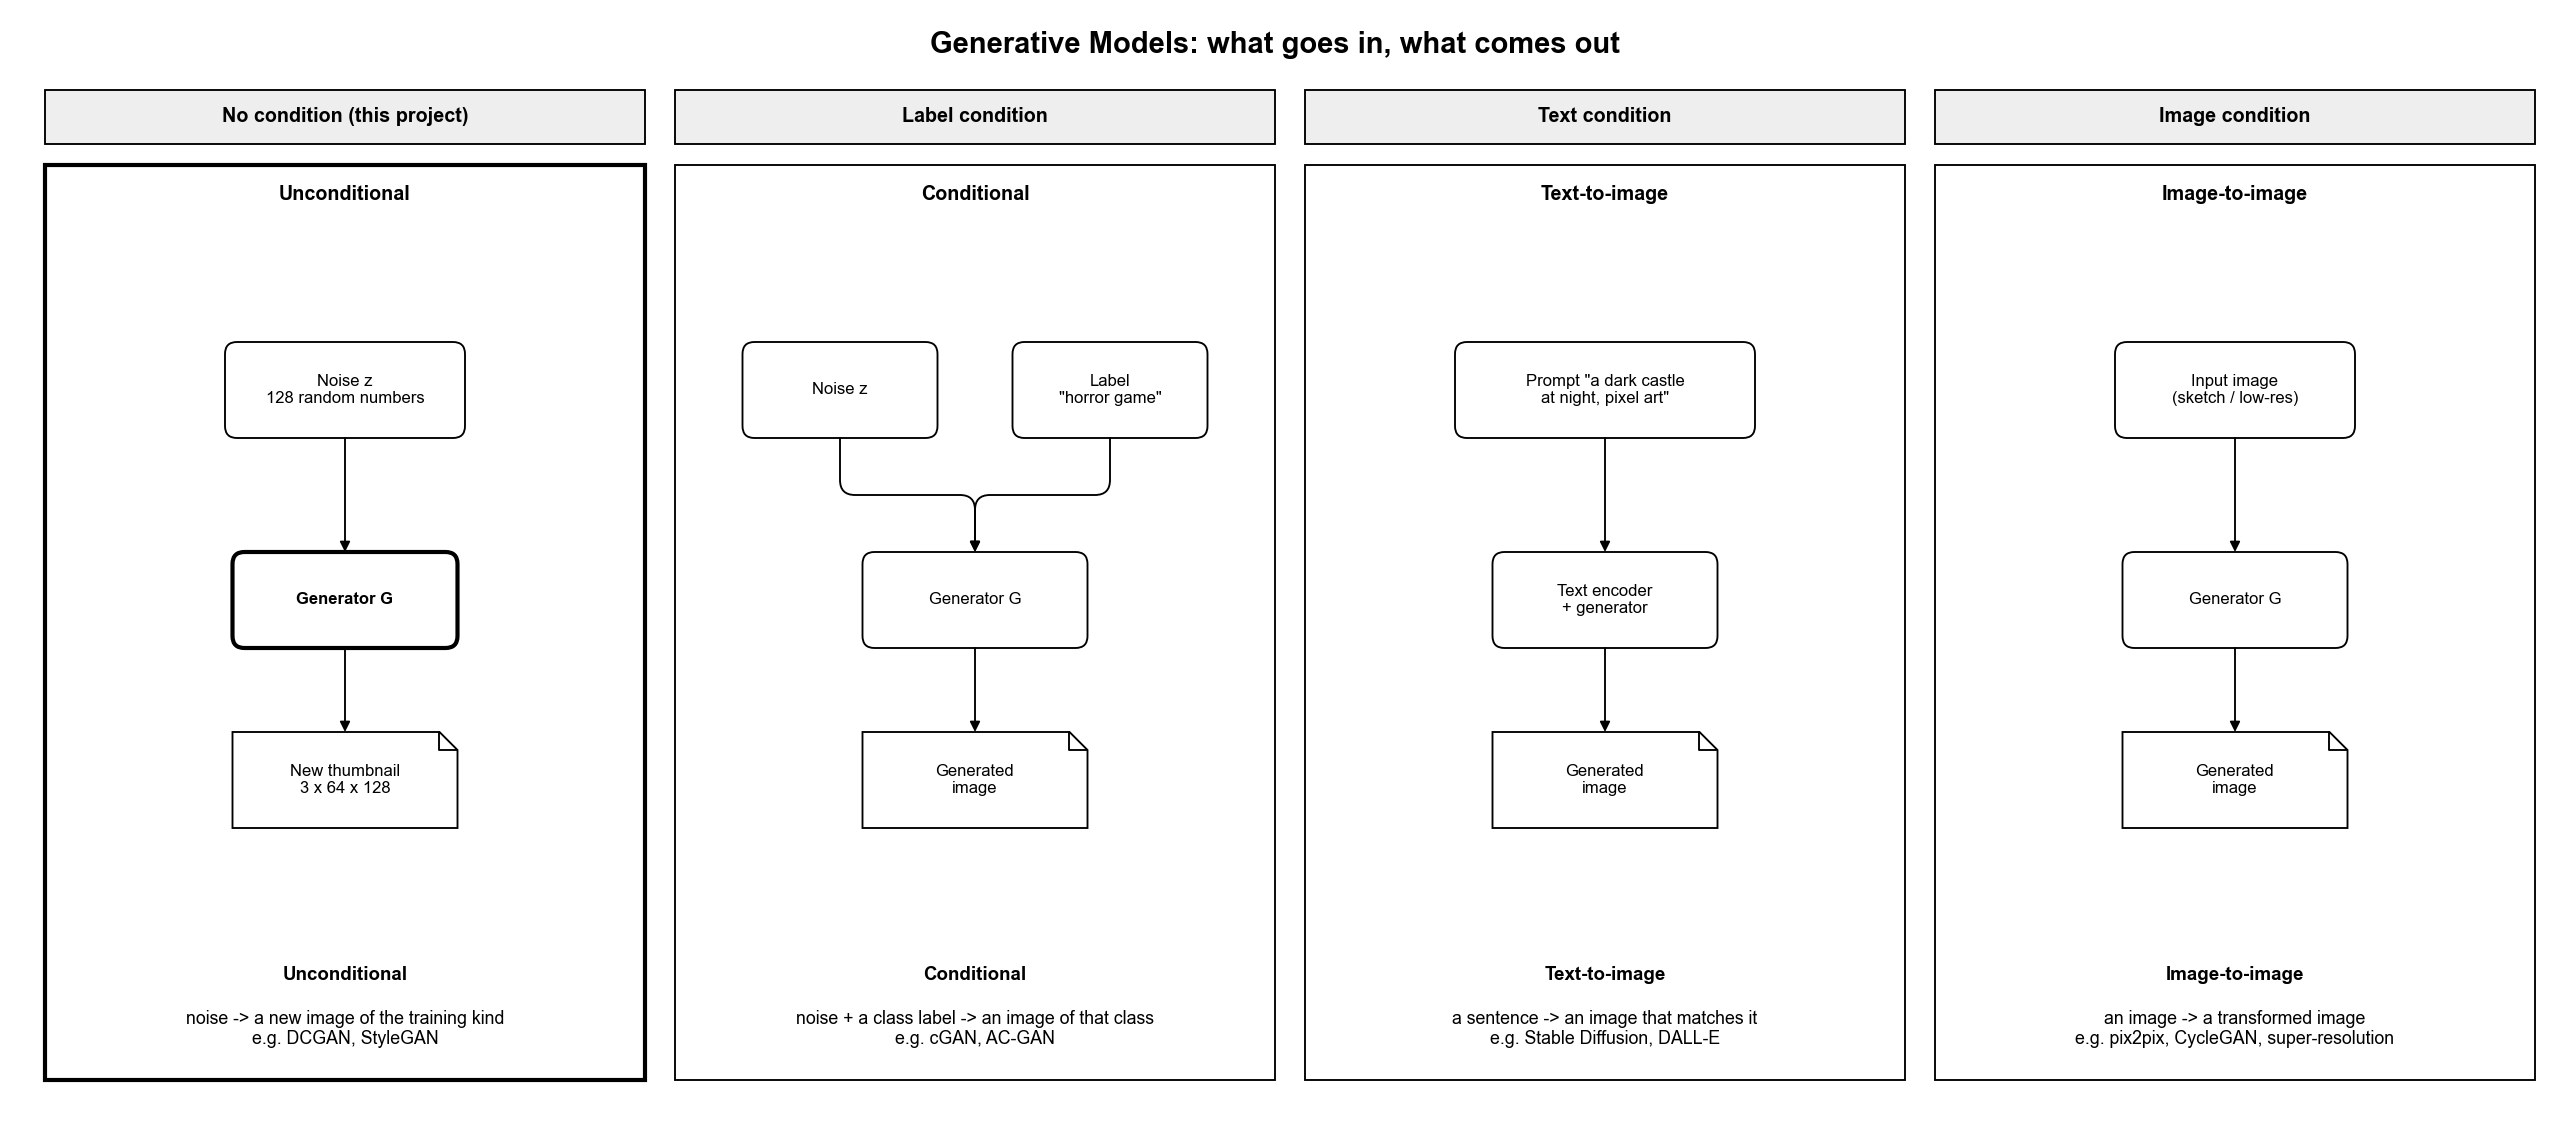

**Aim** → train a GAN that turns 128 random numbers into a new 64 × 128 Steam thumbnail, then check honestly how realistic the fakes are and whether they are copies.

**Objectives**
1. See what real Steam thumbnails look like, as data
2. Understand how a GAN learns, and why training is a balancing act
3. Follow how the generator and discriminator turn noise into an image and back into a verdict
4. Tell whether training works when there is no accuracy to watch
5. Score realism with the Fréchet Inception Distance
6. Check whether the GAN invented new images or memorised training ones
7. Walk through the latent space between two fakes

**Where it could help** → small studios need many quick visual ideas for store banners before paying an artist. The GAN works as a mood-board generator for layouts and colour schemes, not as finished artwork (its letters cannot be read).

# [1/14] Setup

Every setting lives in the next cell. Downloaded images are cached in `WORK_DIR`, so a second run skips the download.

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/12] DATA_DIR: dataset folder (searched recursively for steam_media_data.csv if not found here)
    Default = '/kaggle/input/datasets/nikdavis/steam-store-games'
[2/12] WORK_DIR: folder for the image cache and exported figures
    Default = '/kaggle/working'
[3/12] N_IMAGES: thumbnails downloaded (training set + held-out set)
    Default = 12000
[4/12] N_HOLDOUT: real thumbnails kept out of training, used for FID and the memorisation check
    Default = 2000
[5/12] IMG_H / IMG_W: training size, keeps the 2 : 1 banner shape
    Default = 64 / 128
[6/12] LATENT_DIM: length of the random noise vector z
    Default = 128
[7/12] EPOCHS / BATCH_SIZE: training length
    Default = 100 / 128
[8/12] LR_G / LR_D: learning rates of generator and discriminator (two time-scale update rule)
    Default = 0.0001 / 0.0004
[9/12] DOWNLOAD_WORKERS: parallel downloads
    Default = 32
[10/12] SEED: random seed
    Default = 42
[11/12] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
    For example:
        SAVE_FIGURES = True
[12/12] DISPLAY_SEED: which images are shown in the grids (None = a new random sample on every run)
    Default = None
    For example:
        DISPLAY_SEED = 7
"""
DATA_DIR         = '/kaggle/input/datasets/nikdavis/steam-store-games'
WORK_DIR         = '/kaggle/working'
N_IMAGES         = 12000
N_HOLDOUT        = 2000
IMG_H, IMG_W     = 64, 128
LATENT_DIM       = 128
EPOCHS           = 100
BATCH_SIZE       = 128
LR_G             = 0.0001
LR_D             = 0.0004
DOWNLOAD_WORKERS = 32
SEED             = 42
SAVE_FIGURES     = False
DISPLAY_SEED     = None

ADAM_BETAS       = (0.0, 0.9)             # usual for hinge-loss GANs with spectral normalisation
EMA_DECAY        = 0.999                  # generator weights averaged over training steps (smoother images)
SNAPSHOT_EPOCHS  = (1, 5, 10, 25, 50, 75, 100)
N_GRID           = 48                     # images per grid (6 rows of 8)
N_PROGRESS       = 12                     # images per epoch row in the progress figure
N_WALKS          = 6                      # latent-space walks
N_NOISE_FID      = 2000                   # random-noise images used as the worst-case FID reference
INTERP_STEPS     = 9
PAD              = 32
PALETTE          = {'main': 'black', 'flag': 'red', 'soft': 'grey'}

In [ ]:
import io
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display
from PIL import Image
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm
from torchvision.models import Inception_V3_Weights, inception_v3

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
show_rng = np.random.default_rng(DISPLAY_SEED)      # only decides which images are displayed
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ASSETS = Path(WORK_DIR) / 'assets'
CACHE = Path(WORK_DIR) / f'steam_thumbnails_{N_IMAGES}_{IMG_H}x{IMG_W}.npz'
Path(WORK_DIR).mkdir(parents=True, exist_ok=True)
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)
if DEVICE.type == 'cpu':
    print('(!) No GPU found -> training will be slow. Kaggle: Settings -> Accelerator -> GPU')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_data_dir(default, root='/kaggle/input'):
    """Folder that holds steam_media_data.csv and steam.csv. Tries `default`, then searches `root`."""
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('steam_media_data.csv'))
    for folder in candidates:
        if (folder / 'steam_media_data.csv').is_file() and (folder / 'steam.csv').is_file():
            return folder
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(f'(!) No steam_media_data.csv under {default} or {root}.\n'
                            f'    Add Input -> Datasets -> nikdavis/steam-store-games\n'
                            f'    Mounted now: {mounted or "nothing"}')


def to_display(batch):
    """Tensor in [-1, 1], shape (n, 3, H, W) -> uint8 numpy (n, H, W, 3)."""
    x = ((batch.detach().cpu().clamp(-1, 1) + 1) * 127.5).round().byte()
    return x.permute(0, 2, 3, 1).numpy()


def grid(images, ncols=8):
    """uint8 (n, H, W, 3) -> one big image."""
    n, h, w, c = images.shape
    nrows = int(np.ceil(n / ncols))
    canvas = np.full((nrows * (h + 2), ncols * (w + 2), c), 255, dtype=np.uint8)
    for i, im in enumerate(images):
        r, k = divmod(i, ncols)
        canvas[r * (h + 2): r * (h + 2) + h, k * (w + 2): k * (w + 2) + w] = im
    return canvas

# [2/14] What goes in, what comes out

**What I'm trying to do** → place this model among generative models: it turns random numbers into new thumbnails; it does not read text or edit images.

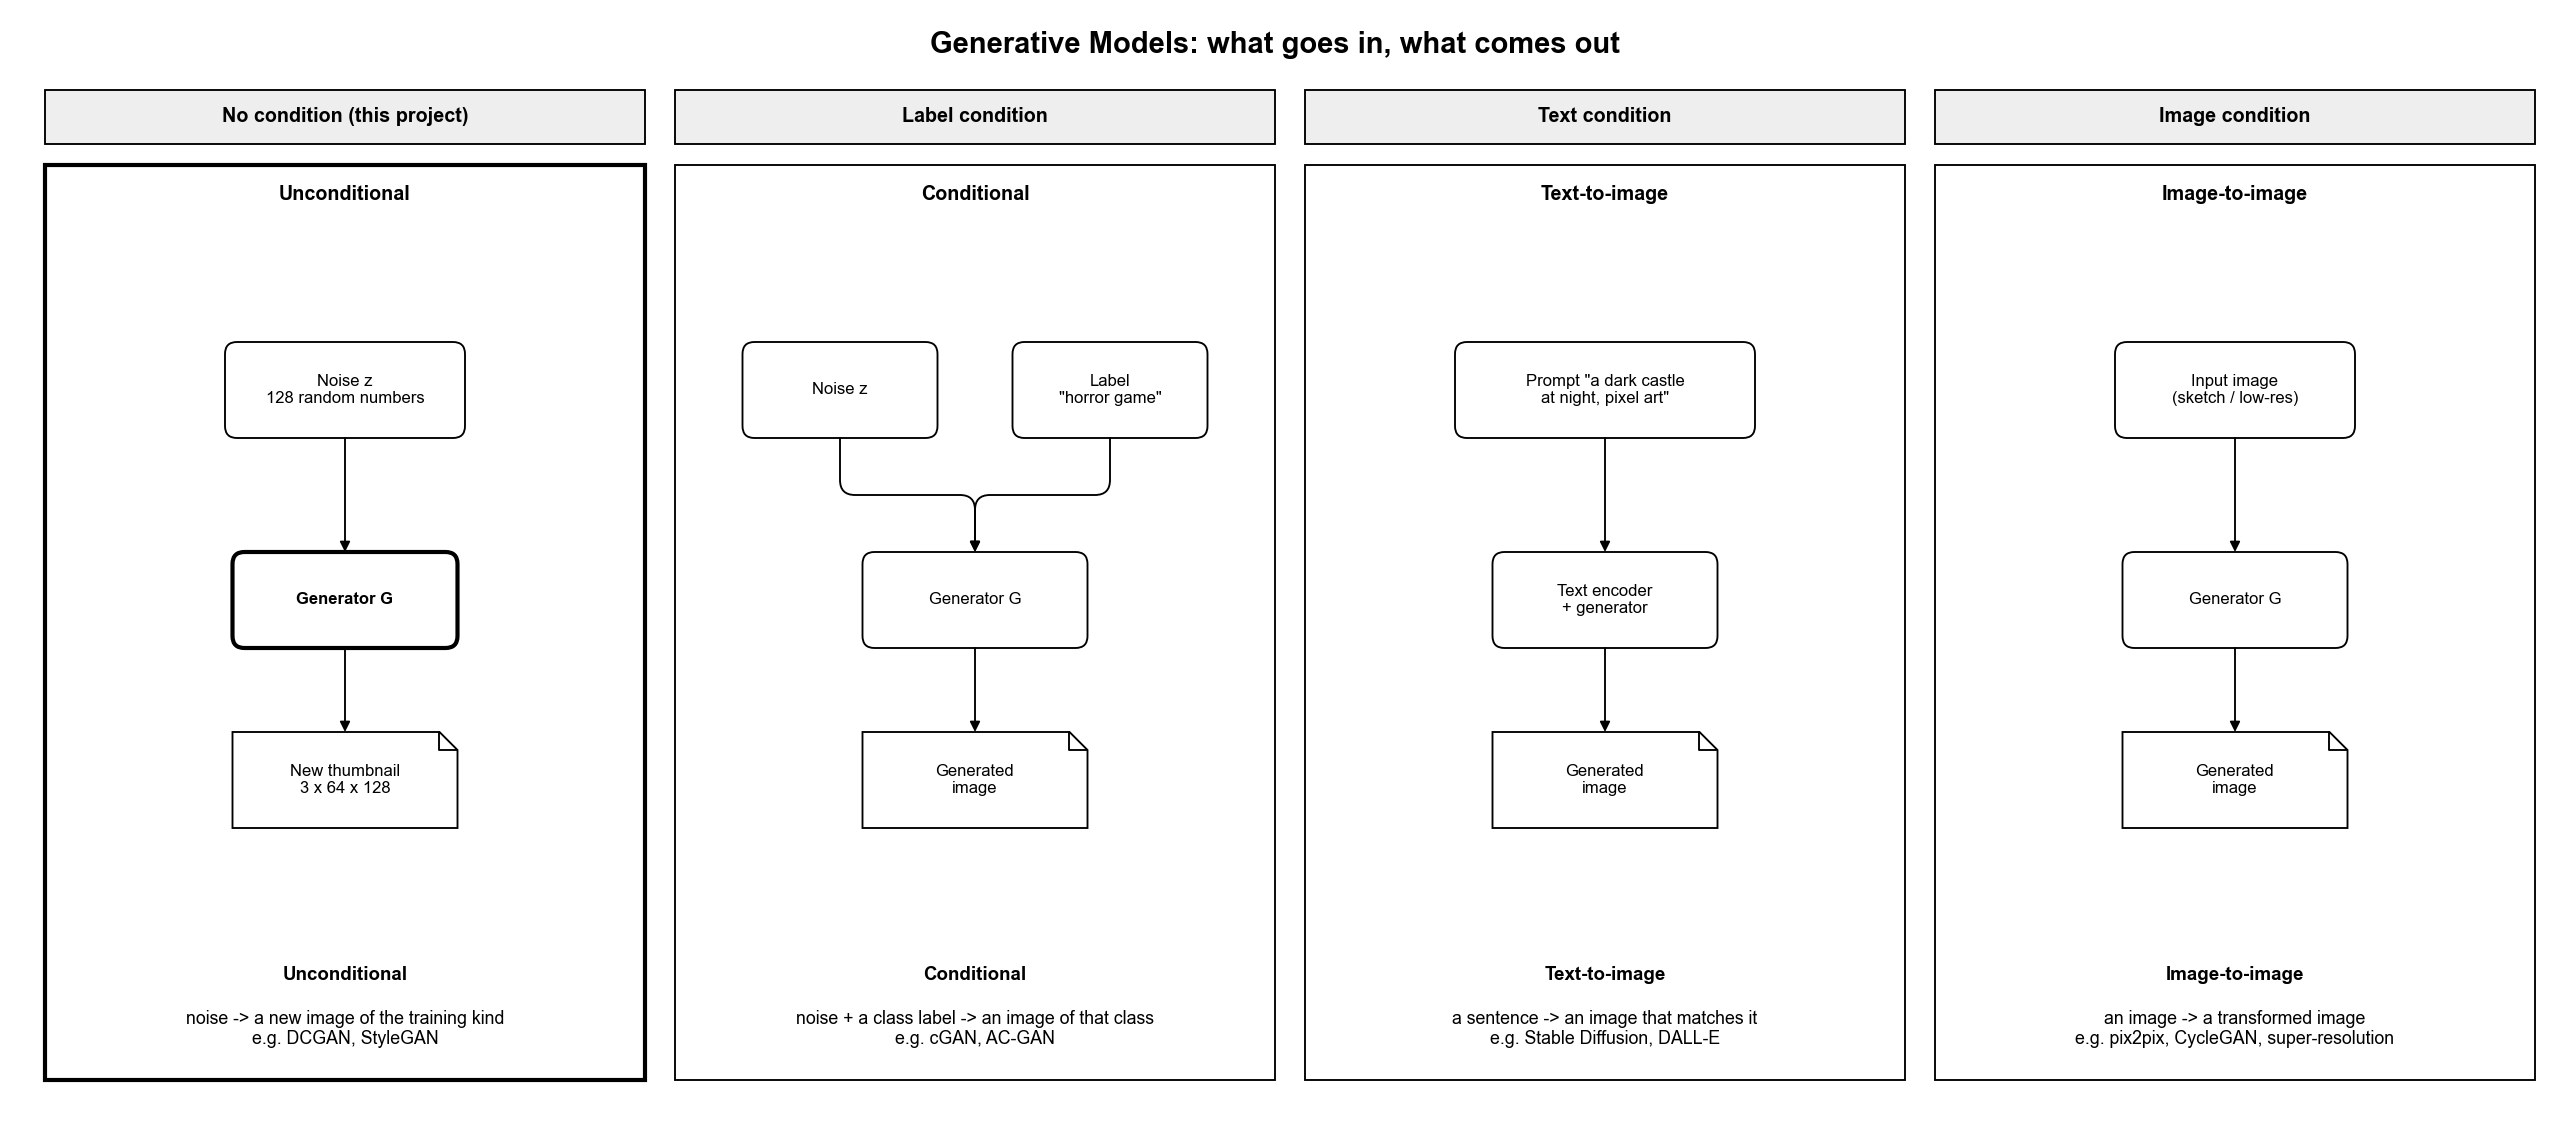

**Question:** Is this text-to-image or image-to-image?

**Answer:** Neither. It is an **unconditional** generator: the only input is random noise.

| | Training | Using the trained model |
|---|---|---|
| **Input** | real thumbnails (for the discriminator) + random noise $z$ (for the generator) | 128 random numbers (a seed) |
| **Output** | better weights for both networks | one new 64 × 128 colour thumbnail |
| **What you control** | the settings in the top cell | only the seed: the same seed gives the same image, nearby seeds give similar images (section 13) |

- **The goal** → learn the *look* of Steam headers (layout, colour mood, title blocks) well enough to invent new ones, then measure how close they get (FID, section 11) and whether they are copies (section 12)
- **Not the goal** → typing "horror game" and getting one; that needs a **conditional** or **text-to-image** model. A genre-conditioned GAN using the recommender's clusters is the natural next step
- In short → I hand the model a lottery-ticket number and it paints a new banner

# [3/14] Data and download

**What I'm trying to do** → sample games, download their header images once, crop them to 2 : 1 and shrink them to 64 × 128, so I end up with a cached array of real thumbnails.

In [ ]:
data_dir = find_data_dir(DATA_DIR)
media = pd.read_csv(data_dir / 'steam_media_data.csv').rename(columns={'steam_appid': 'appid'})
store = pd.read_csv(data_dir / 'steam.csv', usecols=['appid', 'name', 'genres', 'positive_ratings', 'negative_ratings'])
catalogue = store.merge(media[['appid', 'header_image']], on='appid').dropna(subset=['header_image'])
sample = catalogue.sample(n=min(N_IMAGES, len(catalogue)), random_state=SEED).reset_index(drop=True)
show_block('Inputs', {'data folder': data_dir, 'games with a header image': len(catalogue), 'sampled': len(sample),
                      'example URL': sample.loc[0, 'header_image'].split('?')[0]})

In [ ]:
def fetch(url, retries=3):
    """Download one header, centre-crop to 2:1, resize to IMG_W x IMG_H. Returns uint8 array or None."""
    for attempt in range(retries):
        try:
            r = requests.get(url, timeout=15)
            r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)).convert('RGB')
            w, h = im.size
            target_w = min(w, 2 * h)
            left = (w - target_w) // 2
            im = im.crop((left, 0, left + target_w, target_w // 2)).resize((IMG_W, IMG_H), Image.LANCZOS)
            return np.asarray(im, dtype=np.uint8)
        except Exception:
            time.sleep(1 + attempt)
    return None


start = time.time()
if CACHE.exists():
    cached = np.load(CACHE, allow_pickle=True)
    images, kept_appids = cached['images'], cached['appids']
    source = 'cache'
else:
    with ThreadPoolExecutor(DOWNLOAD_WORKERS) as pool:
        results = list(pool.map(fetch, sample['header_image']))
    ok = np.array([r is not None for r in results])
    if ok.sum() == 0:
        raise RuntimeError('(!) No image could be downloaded. Kaggle: Settings -> Internet -> On')
    images = np.stack([r for r in results if r is not None])
    kept_appids = sample.loc[ok, 'appid'].to_numpy()
    np.savez_compressed(CACHE, images=images, appids=kept_appids)
    source = 'download'
meta = sample.set_index('appid').loc[kept_appids].reset_index()

In [ ]:
show_block('Outputs', {'source': source, 'images': images.shape, 'failed downloads': len(sample) - len(images),
                       'seconds': round(time.time() - start, 1), 'cache file': CACHE.name,
                       'cache size (MB)': round(CACHE.stat().st_size / 2 ** 20, 1)})

**Question:** How much data does the GAN get, and in what form?

**Answer:** 11,999 headers (one download failed; about 4 minutes, cached as 214 MB), cropped to 2 : 1, shrunk to 64 × 128 and scaled to [−1, 1]. 9,999 train the GAN; 2,000 are kept aside for evaluation.

In [ ]:
perm = rng.permutation(len(images))
holdout_idx, train_idx = perm[:N_HOLDOUT], perm[N_HOLDOUT:]
X_train = torch.from_numpy(images[train_idx]).permute(0, 3, 1, 2).float().div(127.5).sub(1)     # [-1, 1]
X_hold = torch.from_numpy(images[holdout_idx]).permute(0, 3, 1, 2).float().div(127.5).sub(1)
show_block('Split', {'training thumbnails': len(X_train), 'held-out thumbnails': len(X_hold),
                     'tensor shape': tuple(X_train.shape), 'pixel range': (float(X_train.min()), float(X_train.max()))})

# [4/14] Real thumbnails

**What I'm trying to do** → look at a random grid, the average thumbnail and the colour distribution, to see what the generator has to imitate.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={'width_ratios': [3, 1]})
axes[0].imshow(grid(images[show_rng.choice(train_idx, N_GRID, replace=False)]))
axes[0].set(title=f'{N_GRID} random real Steam thumbnails (64 x 128)', xticks=[], yticks=[])
axes[1].imshow(images[train_idx].mean(axis=0).astype(np.uint8))
axes[1].set(title='Average of all training thumbnails', xticks=[], yticks=[])
fig.tight_layout()
save(fig, '01_real_thumbnails')
plt.show()

In [ ]:
channel_mean = images[train_idx].mean(axis=(0, 1, 2), dtype=np.float64)
brightness = images[train_idx].mean(axis=(1, 2, 3), dtype=np.float64)
show_block('Colour statistics', {'mean R / G / B': tuple(float(v) for v in channel_mean.round(1)),
                                 'mean brightness (0-255)': round(float(brightness.mean()), 1),
                                 'darkest 10 % of thumbnails below': round(float(np.percentile(brightness, 10)), 1),
                                 'brightest 10 % above': round(float(np.percentile(brightness, 90)), 1)})

**Question:** What makes thumbnails hard to generate?

**Answer:** Text and variety.
- most banners carry a stylised logo, and letters need exact shapes
- pixel art, 3-D renders, anime and photos share one dataset; there is no common object like a face
- mostly dark and warm: mean RGB (104.9, 97.9, 93.6), brightness 98.8 / 255

# [5/14] How a GAN learns

**Aim** → understand the game the two networks play: the generator $G$ forges thumbnails from noise, the discriminator $D$ tells real from fake, and each improves by beating the other.

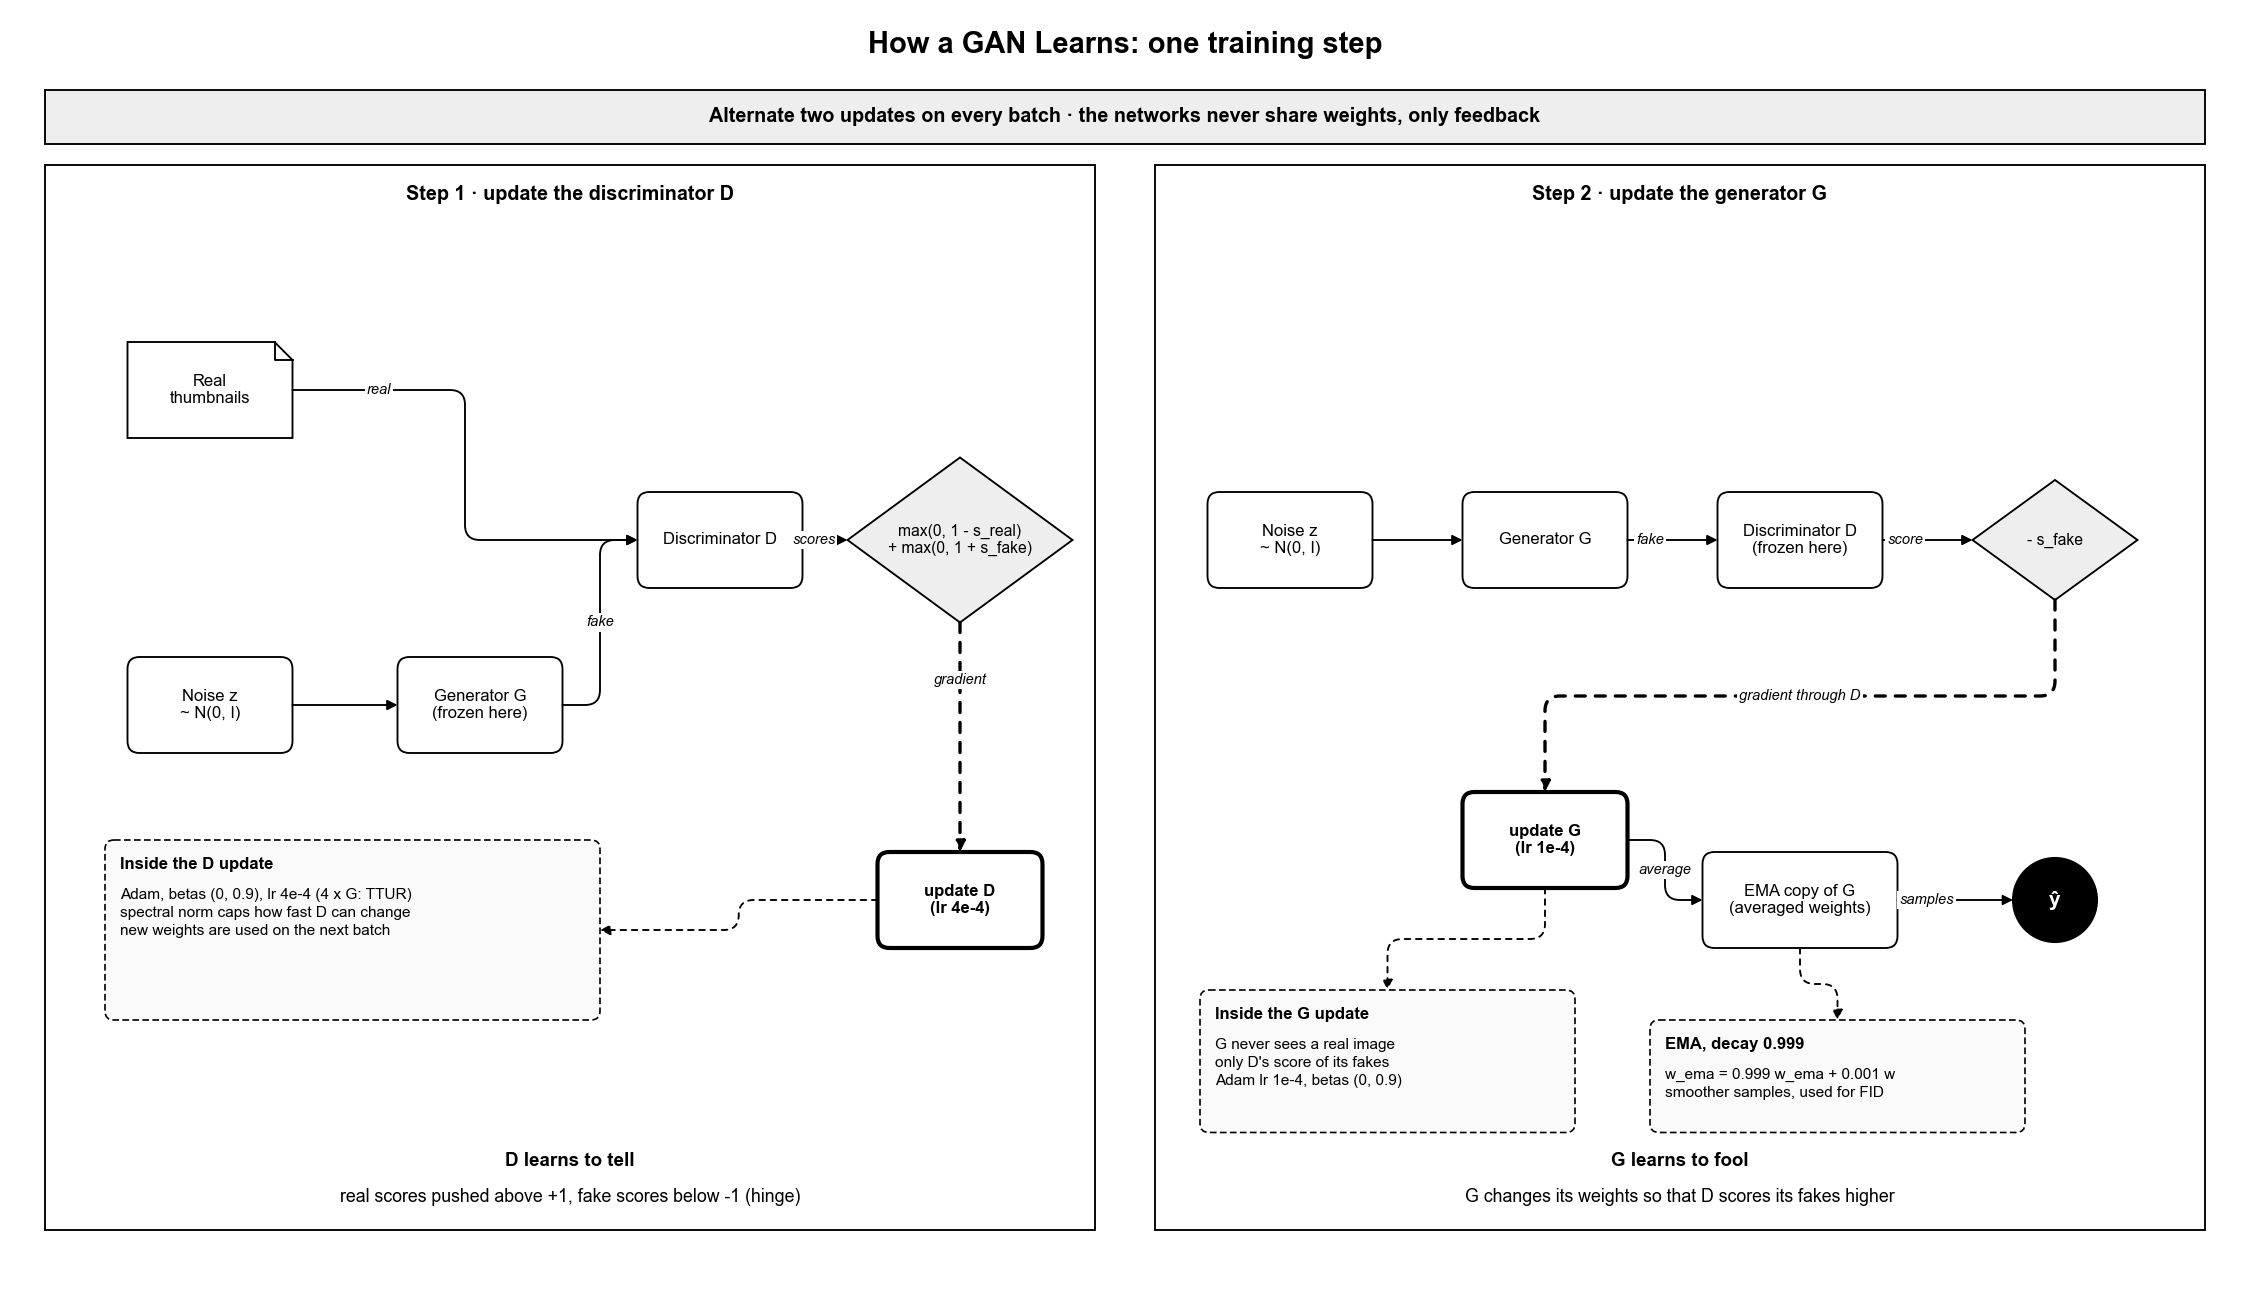

**Question:** What exactly do the two networks optimise?

**Answer:** D learns from real and fake images; G never sees a real image and learns only from D's feedback. If either side wins outright, learning stops; hinge loss, spectral norm and two learning rates keep the contest going.

**GAN in one line** → a forger (G) and a detective (D) train together: every fake D catches tells G how to make the next one more convincing.

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim \mathcal{N}(0, I)}\left[\log\left(1 - D(G(z))\right)\right]$$
- $x$ → a real thumbnail, $z$ → 128 random numbers, $G(z)$ → a forged thumbnail, $D(\cdot)$ → probability "real"
- **Equilibrium** → if G copied the real distribution perfectly, the best D could do is guess: $D = 0.5$ everywhere
- In short → the contest ends when the detective can only flip a coin

**How one training step works, in 4 steps**
1. Show D a batch of real thumbnails and a batch of G's fakes; update D to score real higher and fake lower
2. Freeze D, make a new batch of fakes, and update G so D scores them higher
3. Update the averaged copy of G (EMA) used for samples
4. Repeat for every batch, 100 epochs

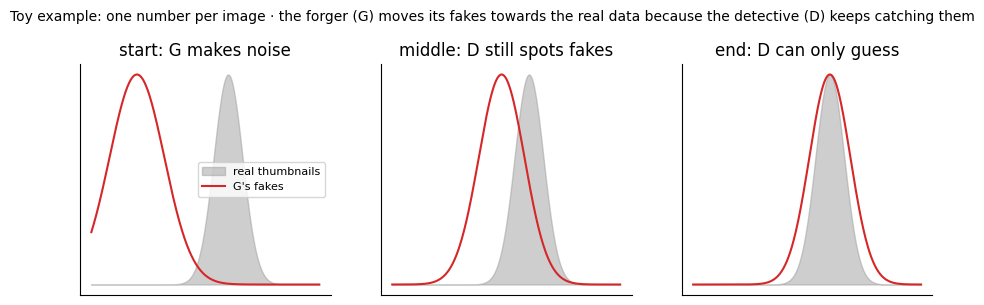

**Hinge loss in one line** → D outputs a score $s$ and is only pushed until real scores are above +1 and fake scores below −1, so it never becomes infinitely sure.

$$L_D = \mathbb{E}\left[\max(0, 1 - s(x))\right] + \mathbb{E}\left[\max(0, 1 + s(G(z)))\right] \qquad L_G = -\mathbb{E}\left[s(G(z))\right]$$
- In short → once D is "sure enough", it stops pushing and leaves room for G to learn

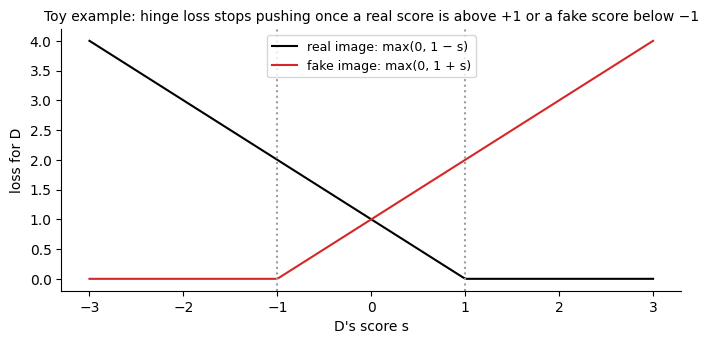

**Spectral normalisation in one line** → divide each D layer's weights by their largest stretch factor, so a small change in an image can only make a small change in D's score (Miyato et al. 2018).

**How the stabilisers help, in 4 steps**
1. **Spectral norm** → keeps D smooth, so G always gets a usable direction
2. **Two learning rates (TTUR)** → D learns 4× faster than G (4e-4 vs 1e-4), so D stays a useful judge
3. **Upsample + convolution** in G → avoids the checkerboard of transposed convolutions (section 6)
4. **EMA** → an averaged copy of G's weights gives calmer, cleaner samples

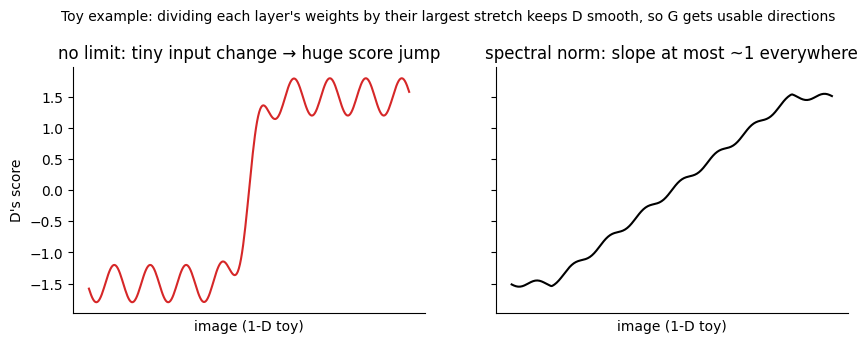

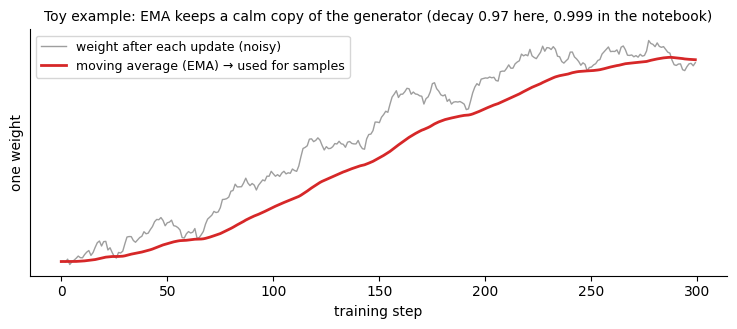

My first attempt used the plain DCGAN recipe (BCE loss, transposed convolutions): D won early, and the images showed checkerboard patterns and FID 227.

# [6/14] Architecture

**What I'm trying to do** → build the generator (noise → 4 × 8 → … → 64 × 128 image, upsample + convolution) and the spectral-normalised discriminator, and count their parameters.

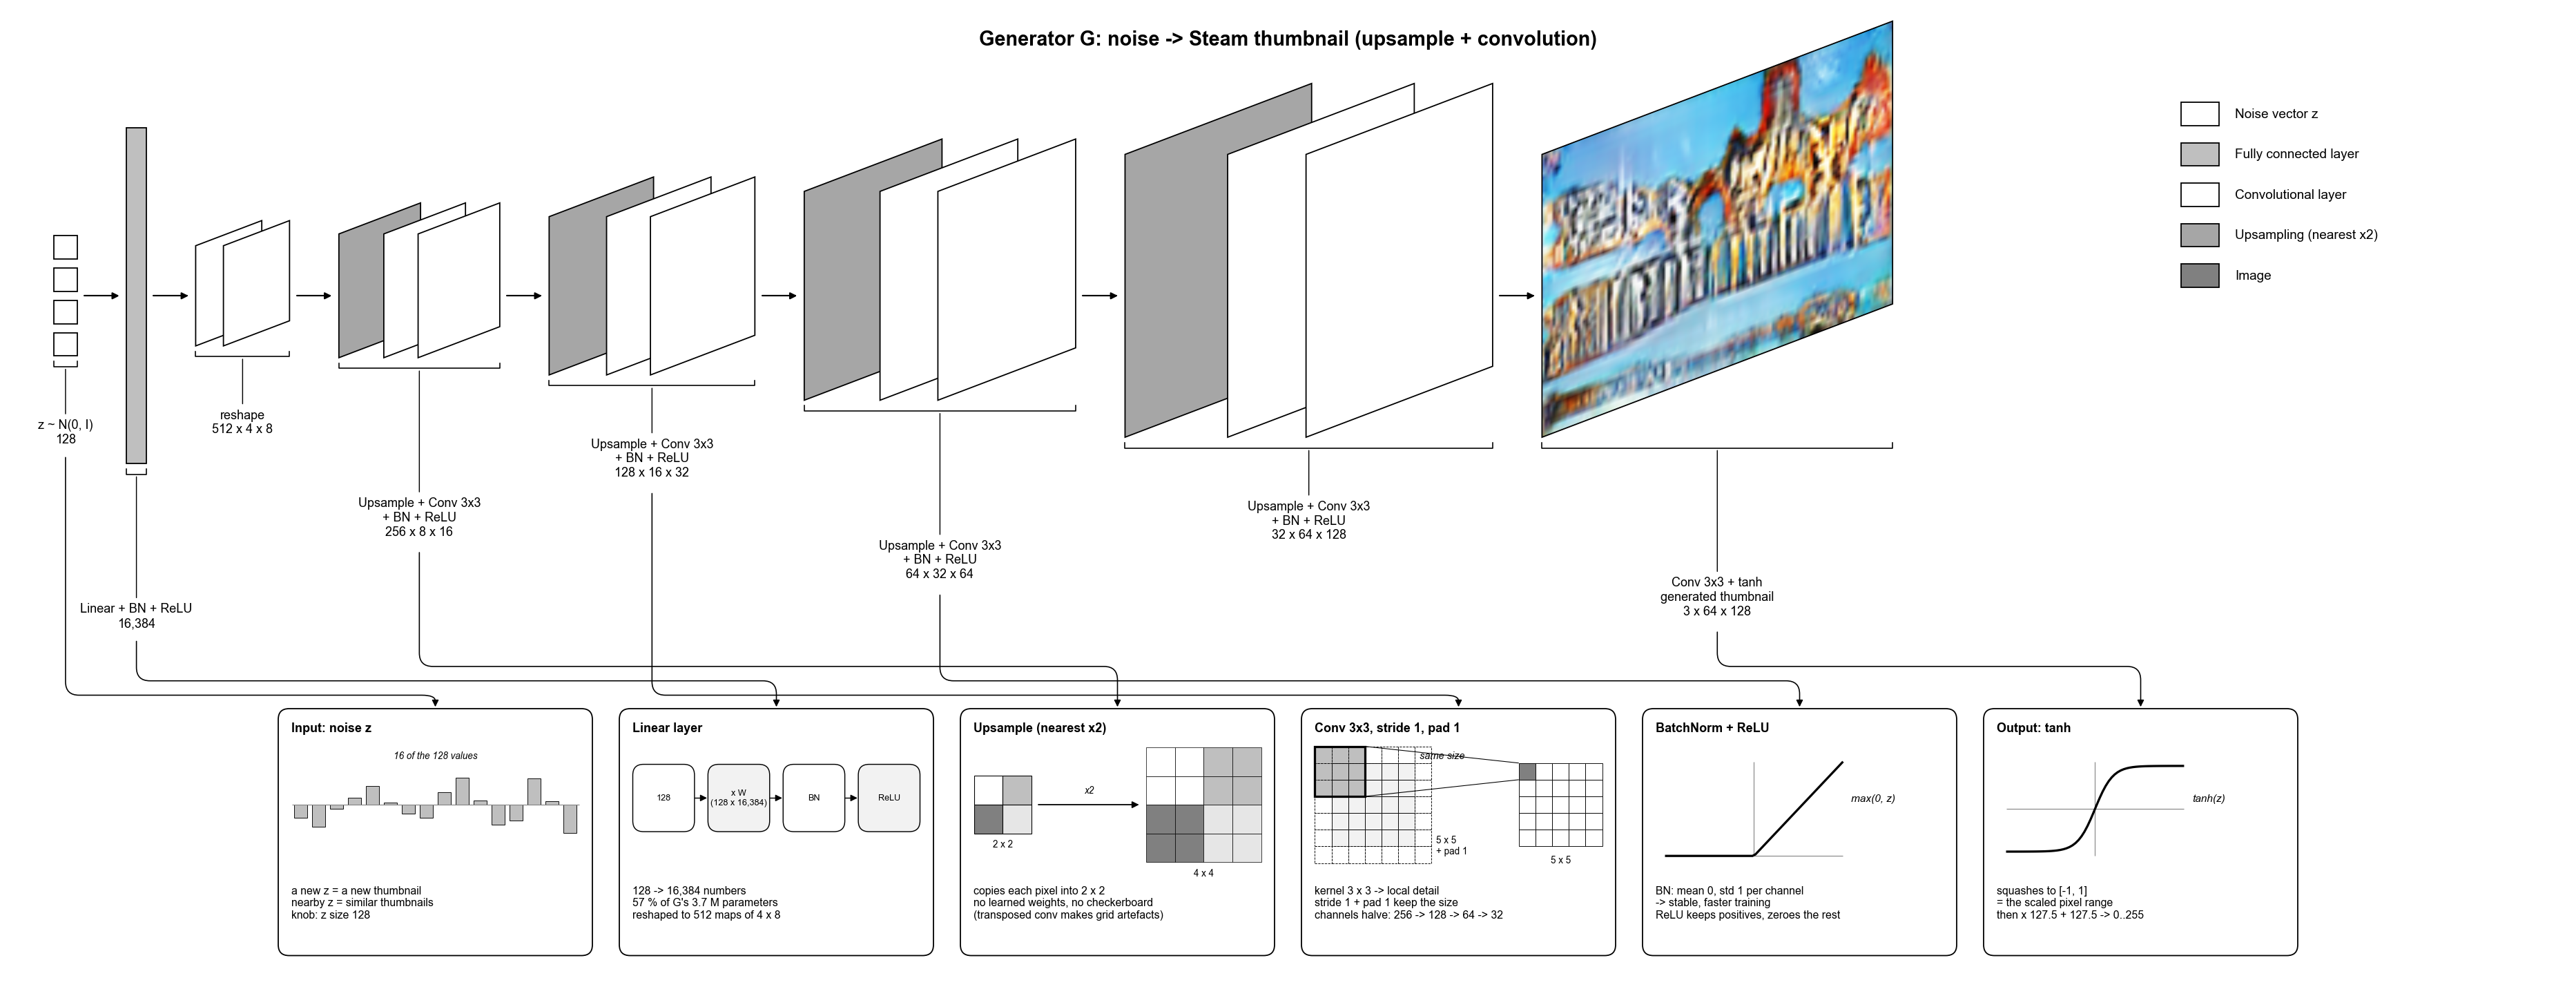

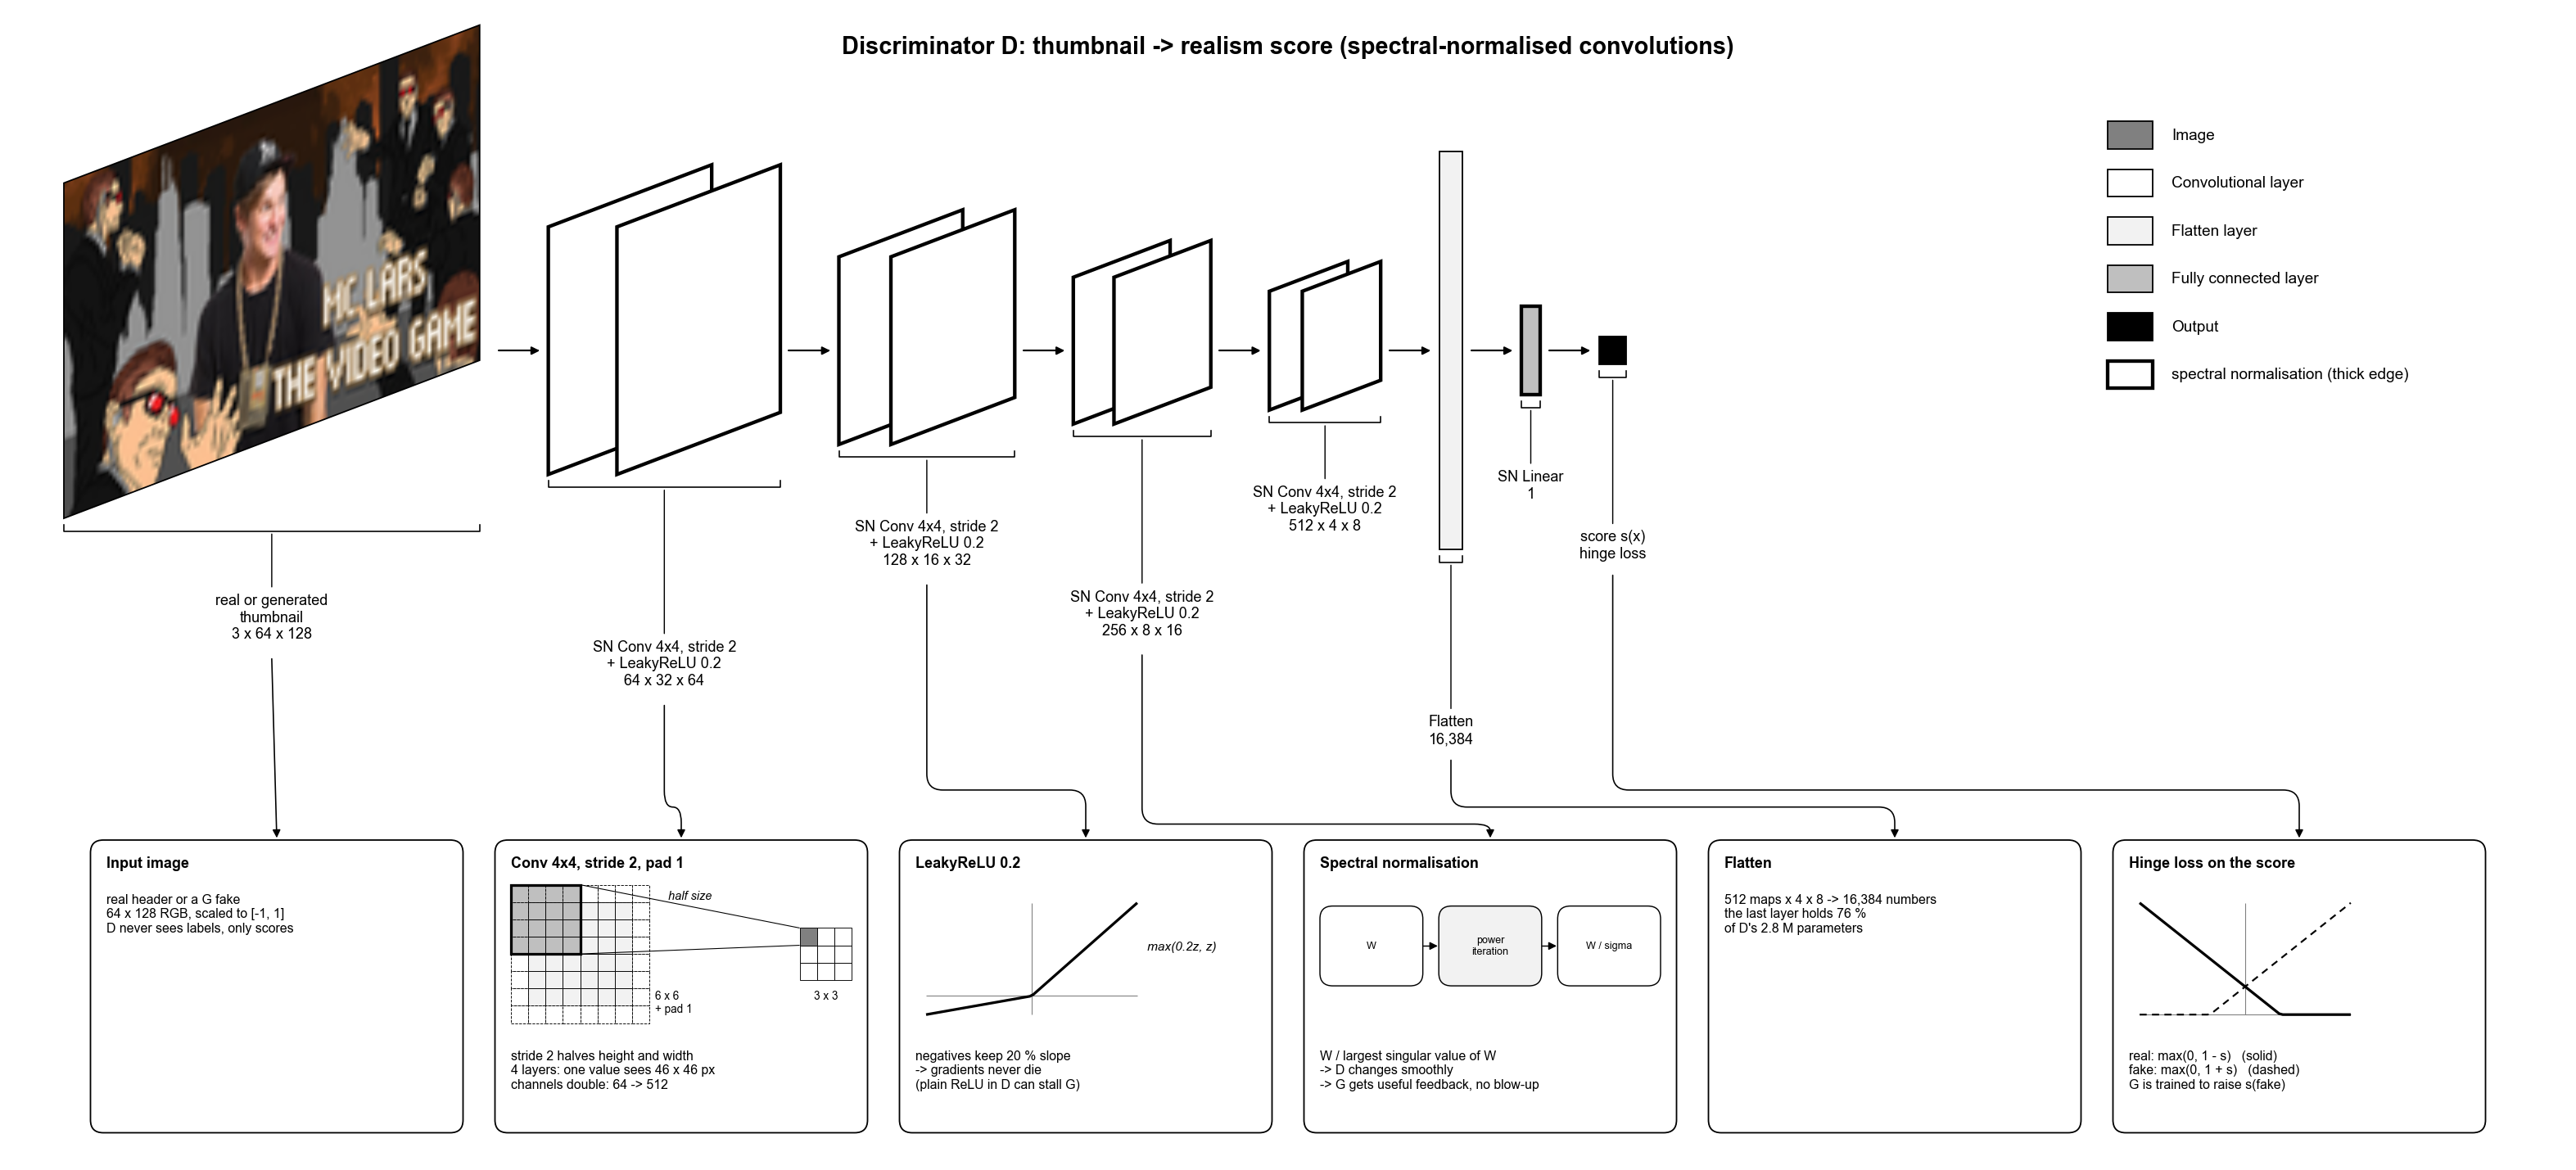

**Upsample + convolution in one line** → to make the image bigger, first copy every pixel into a 2 × 2 block, then let a normal convolution add detail.

**How, in 3 steps**
1. Nearest-neighbour upsampling doubles height and width (4 × 8 → 8 × 16)
2. A 3 × 3 convolution with padding 1 turns the blocky copy into detail
3. Batch norm + ReLU, then repeat until 64 × 128

- In short → transposed convolutions overlap unevenly and leave a grid; copying first keeps every pixel equally covered

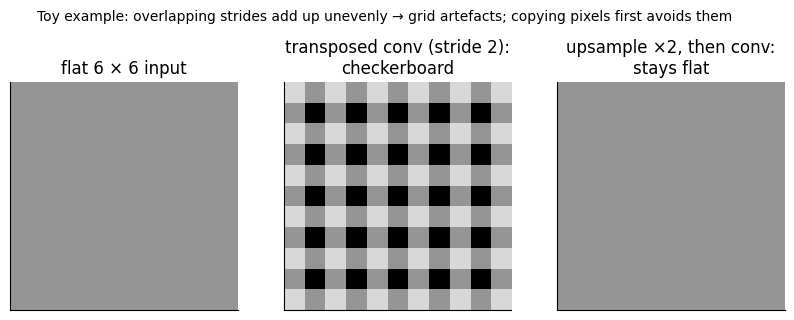

In [ ]:
class Generator(nn.Module):
    """z (128) -> dense 512 x 4 x 8 -> 4 x [upsample x2 + conv 3x3 + BN + ReLU] -> conv 3x3 -> tanh -> 3 x 64 x 128"""
    def __init__(self, z=LATENT_DIM, f=64):
        super().__init__()
        self.f = f
        self.fc = nn.Sequential(nn.Linear(z, f * 8 * 4 * 8, bias=False), nn.BatchNorm1d(f * 8 * 4 * 8), nn.ReLU(True))
        def up(cin, cout):
            return [nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(cin, cout, 3, 1, 1, bias=False),
                    nn.BatchNorm2d(cout), nn.ReLU(True)]
        self.net = nn.Sequential(*up(f * 8, f * 4),          # 8 x 16
                                 *up(f * 4, f * 2),          # 16 x 32
                                 *up(f * 2, f),              # 32 x 64
                                 *up(f, f // 2),             # 64 x 128
                                 nn.Conv2d(f // 2, 3, 3, 1, 1), nn.Tanh())

    def forward(self, z):
        return self.net(self.fc(z).view(z.size(0), self.f * 8, 4, 8))


class Discriminator(nn.Module):
    """3 x 64 x 128 -> 4 x [spectral-norm conv 4x4 stride 2 + LeakyReLU] -> 512 x 4 x 8 -> spectral-norm linear -> score"""
    def __init__(self, f=64):
        super().__init__()
        def down(cin, cout):
            return [spectral_norm(nn.Conv2d(cin, cout, 4, 2, 1)), nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*down(3, f),                # 32 x 64
                                 *down(f, f * 2),            # 16 x 32
                                 *down(f * 2, f * 4),        # 8 x 16
                                 *down(f * 4, f * 8))        # 4 x 8
        self.out = spectral_norm(nn.Linear(f * 8 * 4 * 8, 1))

    def forward(self, x):
        return self.out(self.net(x).flatten(1)).view(-1)


G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
G_ema = Generator().to(DEVICE)
G_ema.load_state_dict(G.state_dict())
G_ema.eval()
with torch.no_grad():
    shape_g = tuple(G(torch.randn(2, LATENT_DIM, device=DEVICE)).shape)
    shape_d = tuple(D(torch.randn(2, 3, IMG_H, IMG_W, device=DEVICE)).shape)

In [ ]:
show_block('Networks', {'device': DEVICE, 'generator parameters': f'{sum(p.numel() for p in G.parameters()):,}',
                        'discriminator parameters': f'{sum(p.numel() for p in D.parameters()):,}',
                        'G: z (2, 128) ->': shape_g, 'D: image (2, 3, 64, 128) ->': shape_d})

# [7/14] Inside the networks: layers, activations and knobs

**What I'm trying to do** → read the two networks layer by layer, see why each activation sits where it does, and learn which knob changes what, as a short reference before training.

## 7.1 Layers, shapes and parameters

$$\text{output size} = \frac{\text{input} + 2 \cdot \text{padding} - \text{kernel}}{\text{stride}} + 1 \qquad \text{parameters of a conv} = \text{kernel}^2 \times C_{in} \times C_{out}$$
- **Stride 2** → halves the image (64 → 32): the discriminator zooms out step by step
- **Upsample + conv** → doubles the image (32 → 64): the generator zooms in step by step
- **Parameters** grow with the *product* of channels, so the widest layers hold almost everything
- In short → the cost of a layer is in how many channels it mixes, not in how big the picture is

In [ ]:
def layer_table(model, x):
    rows, hooks = [], []
    for name, module in model.named_modules():
        if len(list(module.children())) == 0:
            hooks.append(module.register_forward_hook(lambda mod, inp, out, name=name: rows.append({
                'layer (type)': f'{name} ({mod.__class__.__name__})',
                'kernel / stride': (f'{mod.kernel_size[0]}x{mod.kernel_size[1]} / {mod.stride[0]}' if hasattr(mod, 'kernel_size') and
                                    isinstance(mod.kernel_size, tuple) else '-'),
                'output shape': tuple(out.shape[1:]),
                'parameters': sum(p.numel() for p in mod.parameters(recurse=False))})))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(x)
    model.train(was_training)
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


g_table = layer_table(G, torch.randn(2, LATENT_DIM, device=DEVICE))
d_table = layer_table(D, torch.randn(2, 3, IMG_H, IMG_W, device=DEVICE))

In [ ]:
display(g_table)
display(d_table)
show_block('Total parameters', {'generator': f"{g_table['parameters'].sum():,}", 'discriminator': f"{d_table['parameters'].sum():,}"})

**Answer:** Parameters sit where the channels are many, not where the image is big.
- G (3.7 M): the first linear layer holds 57 % (128 numbers → 16,384 values); the final 64 × 128 layers are cheap
- D (2.8 M): the last convolution holds 76 %; after four stride-2 layers one value sees 46 × 46 pixels

## 7.2 Activation functions

$$\text{ReLU}(x) = \max(0, x) \qquad \text{LeakyReLU}(x) = \max(0.2x, x) \qquad \tanh(x) \in [-1, 1]$$
- **ReLU** (generator) → passes positive signals unchanged, blocks negative ones; fast and simple
- **LeakyReLU** (discriminator) → like ReLU but lets a little negative signal through, so the generator *always* gets feedback
- **tanh** (generator output) → squeezes pixels into $[-1, 1]$, the same range as the training images
- **Problem** → tanh and sigmoid go flat for large inputs (gradient ≈ 0, learning stalls) · **Solution** → ReLU-type functions inside the network
- In short → ReLU-types inside for fast learning, tanh at the end to land in the pixel range

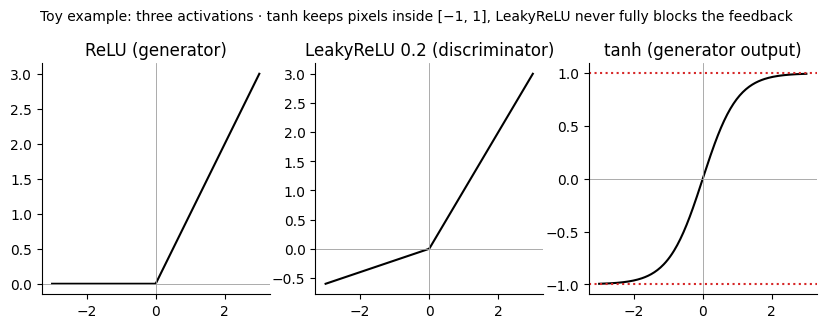

In [ ]:
z_axis = torch.linspace(-4, 4, 401, requires_grad=True)
acts = {'ReLU': F.relu, 'LeakyReLU (0.2)': lambda t: F.leaky_relu(t, 0.2), 'tanh': torch.tanh}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (name, fn), color in zip(acts.items(), ['black', 'red', 'grey']):
    y = fn(z_axis)
    grad, = torch.autograd.grad(y.sum(), z_axis)
    axes[0].plot(z_axis.detach(), y.detach(), label=name, color=color)
    axes[1].plot(z_axis.detach(), grad, label=name, color=color)
axes[0].set(title='Activation', xlabel='input', ylim=(-1.5, 4))
axes[1].set(title='Gradient it passes back', xlabel='input', ylim=(-0.1, 1.1))
for ax in axes:
    ax.legend()
fig.tight_layout()
save(fig, '02_activations')
plt.show()

## 7.3 Knobs: what they control and what you trade

| Knob | Here | Controls | Turn it up → | You trade |
|---|---|---|---|---|
| `LATENT_DIM` | 128 | variety the generator can express | more varied images | variety vs. harder training |
| filters per layer | 64 | model capacity (params ∝ filters²) | sharper detail | detail vs. memory, time, over-fitting |
| blocks (depth) | 4 | image size (×2 each) | bigger images | resolution vs. stability |
| `LR_D` / `LR_G` | 4e-4 / 1e-4 | how fast each network learns | faster learning | speed vs. unstable, one-sided game |
| `BATCH_SIZE` | 128 | noise in each update | smoother updates | stability vs. memory, fewer updates |
| `EPOCHS` | 100 | training length | better images, then a plateau | quality vs. compute |
| `EMA_DECAY` | 0.999 | smoothing of generator weights | calmer, cleaner samples | smoothness vs. slow start |
| spectral norm | on | how sharply $D$ can react | stabler gradients | stability vs. a weaker $D$ |

**Rule of thumb** → keep G and D balanced: if D wins (its loss → 0), lower `LR_D` or weaken D; if images stop improving, train longer or add capacity.

# [8/14] Training

**What I'm trying to do** → alternate one discriminator step and one generator step per batch for 100 epochs, and keep the losses, D's scores and snapshots of the averaged generator on a fixed noise batch.

In [ ]:
opt_d = torch.optim.Adam(D.parameters(), lr=LR_D, betas=ADAM_BETAS)
opt_g = torch.optim.Adam(G.parameters(), lr=LR_G, betas=ADAM_BETAS)
fixed_z = torch.randn(N_GRID, LATENT_DIM, device=DEVICE)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True,
                                     drop_last=True, generator=torch.Generator().manual_seed(SEED))
history, snapshots = [], {}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    sums = np.zeros(4)
    for (real,) in loader:
        real = real.to(DEVICE, non_blocking=True)
        b = real.size(0)
        # --- discriminator (hinge): push real scores above +1 and fake scores below -1
        fake = G(torch.randn(b, LATENT_DIM, device=DEVICE))
        s_real, s_fake = D(real), D(fake.detach())
        loss_d = F.relu(1 - s_real).mean() + F.relu(1 + s_fake).mean()
        opt_d.zero_grad(set_to_none=True); loss_d.backward(); opt_d.step()
        # --- generator: raise the discriminator's score of fakes
        loss_g = -D(fake).mean()
        opt_g.zero_grad(set_to_none=True); loss_g.backward(); opt_g.step()
        # --- exponential moving average of the generator weights
        with torch.no_grad():
            for p_ema, p in zip(G_ema.parameters(), G.parameters()):
                p_ema.lerp_(p, 1 - EMA_DECAY)
            for b_ema, b_ in zip(G_ema.buffers(), G.buffers()):
                b_ema.copy_(b_)
        sums += [loss_d.item(), loss_g.item(), s_real.mean().item(), s_fake.mean().item()]
    n = len(loader)
    history.append({'epoch': epoch, 'loss D': sums[0] / n, 'loss G': sums[1] / n, 'score real': sums[2] / n, 'score fake': sums[3] / n})
    if epoch in SNAPSHOT_EPOCHS:
        with torch.no_grad():
            snapshots[epoch] = to_display(G_ema(fixed_z))
    if epoch == 1 or epoch % 10 == 0:
        h = history[-1]
        print(f"[{epoch}/{EPOCHS}] loss D {h['loss D']:.3f} | loss G {h['loss G']:.3f} | score real {h['score real']:.2f} | "
              f"score fake {h['score fake']:.2f} | {time.time() - start:.0f} s")
history = pd.DataFrame(history).set_index('epoch')
train_seconds = time.time() - start
G = G_ema                                      # every later cell uses the averaged generator
torch.save({'state_dict': G_ema.state_dict(), 'latent_dim': LATENT_DIM, 'img_h': IMG_H, 'img_w': IMG_W},
           Path(WORK_DIR) / 'generator_ema.pt')

In [ ]:
show_block('Training', {'epochs': EPOCHS, 'batches per epoch': len(loader), 'seconds': round(train_seconds, 1),
                        'final score real / fake': (round(history['score real'].iloc[-1], 2), round(history['score fake'].iloc[-1], 2)),
                        'saved generator': 'generator_ema.pt'})

# [9/14] Training curves

**Aim** → read the losses and D's average verdicts per epoch. In a GAN a falling loss is **not** the goal; balance is.

**Question:** How do I know a GAN is training well when there is no accuracy?

- **Losses** → D's hinge loss → 0 would mean D separates real and fake perfectly and G gets no useful signal; a loss that stays near 1-2 means a real contest
- **Scores** → the average score of real and fake images; a gap that stays moderate (instead of growing forever) means neither side wins outright
- **Mode collapse** → G finds a few images that fool D and produces only those: visible as near-identical images in a grid
- In short → I watch for balance and variety, not for a number going down

**Answer:** Balanced for all 100 epochs.
- D loss 1.33–1.53 (a perfect D would reach 0); real ≈ +0.3, fake ≈ −0.5, and the gap is not growing
- no mode collapse: the 48 samples in section 10 all differ
- the plain DCGAN first attempt was dominated by D (0.78 vs 0.12)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(history.index, history['loss D'], color=PALETTE['main'], label='discriminator')
axes[0].plot(history.index, history['loss G'], color=PALETTE['flag'], label='generator')
axes[0].set(title='Loss per epoch', xlabel='epoch')
axes[0].legend()
axes[1].plot(history.index, history['score real'], color=PALETTE['main'], label='real images')
axes[1].plot(history.index, history['score fake'], color=PALETTE['flag'], label='generated images')
axes[1].axhline(0, color=PALETTE['soft'], ls='--', lw=1)
axes[1].set(title="Discriminator's average score", xlabel='epoch')
axes[1].legend()
fig.tight_layout()
save(fig, '03_training_curves')
plt.show()

In [ ]:
display(history.iloc[[0, 4, 9, 24, 49, 74, -1]].round(3))

# [10/14] What the generator learned, epoch by epoch

**What I'm trying to do** → show the same 12 random noise vectors at each snapshot, to see what G learns first: colour and layout, then shapes and logo-like text blocks.

In [ ]:
shown = show_rng.choice(N_GRID, N_PROGRESS, replace=False)          # same random noise vectors in every row
fig, axes = plt.subplots(len(snapshots), 1, figsize=(24, 2.4 * len(snapshots)))
for ax, (ep, ims) in zip(axes, snapshots.items()):
    ax.imshow(grid(ims[shown], ncols=N_PROGRESS))
    ax.set(xticks=[], yticks=[])
    ax.set_ylabel(f'epoch {ep}', rotation=0, ha='right', va='center', fontsize=12)
fig.tight_layout()
save(fig, '04_progress')
plt.show()

In [ ]:
with torch.no_grad():
    fresh = to_display(G(torch.from_numpy(show_rng.standard_normal((N_GRID, LATENT_DIM))).float().to(DEVICE)))
fig, ax = plt.subplots(figsize=(22, 8))
ax.imshow(grid(fresh))
ax.set(title=f'{N_GRID} generated thumbnails after {EPOCHS} epochs', xticks=[], yticks=[])
save(fig, '05_generated')
plt.show()

**Question:** What did the generator learn, and in what order?

**Answer:** Noise (epochs 1–10, while the moving average still remembers the start) → colour blobs (25) → banner layouts with title-like blocks (50+). By epoch 100: varied colour moods and sharper shapes; the "text" looks like text but cannot be read, and a few samples show a faint grid texture.

# [11/14] How realistic? Fréchet Inception Distance

**Aim** → compare generated and real thumbnails through the eyes of an ImageNet-trained Inception network, giving one number where lower is better.

**Question:** How do I score realism without asking humans?

**Answer:** FID **101–122** over two runs: far better than noise (380), far from real (26). The plain DCGAN scored 227. Colours and layouts are learned; objects and readable text are not.

**FID in one line** → describe every image with 2,048 Inception features, summarise real and fake images as two clouds, and measure how far apart the clouds are.

$$\text{FID} = \lVert \mu_r - \mu_g \rVert^2 + \text{Tr}\left(\Sigma_r + \Sigma_g - 2\,(\Sigma_r \Sigma_g)^{1/2}\right)$$
- $\mu, \Sigma$ → mean and covariance of the features for real ($r$) and generated ($g$) images
- **References** → real vs real (the best possible score at this sample size) and random noise vs real (the worst)
- (!) FID depends on sample size and image size; compare numbers only within this notebook
- In short → not "does this one fake look real?" but "do the fakes as a group look like the real ones as a group?"

**How, in 3 steps**
1. Run 2,000 real and 2,000 generated thumbnails through Inception-v3 and keep the 2,048-number feature vector of each
2. Compute the mean and covariance of each group
3. Add the distance between the means and the difference between the covariances

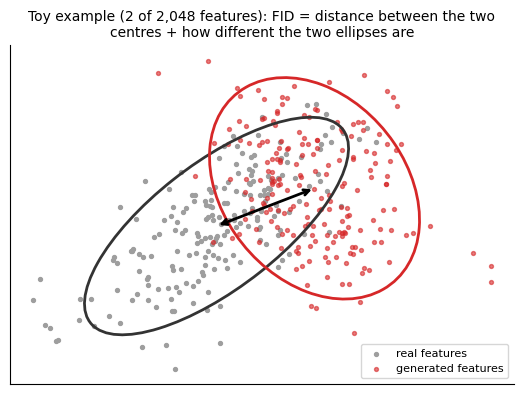

In [ ]:
weights = Inception_V3_Weights.DEFAULT
inception = inception_v3(weights=weights, progress=False, aux_logits=True).to(DEVICE).eval()
inception.fc = nn.Identity()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


@torch.no_grad()
def inception_features(x, batch=100):
    feats = []
    for i in range(0, len(x), batch):
        b = x[i:i + batch].to(DEVICE)
        b = F.interpolate((b + 1) / 2, size=(299, 299), mode='bilinear', align_corners=False)
        feats.append(inception((b - MEAN) / STD).cpu().numpy().astype(np.float64))
    return np.concatenate(feats)


def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))


n_fid = len(X_hold)
with torch.no_grad():
    gen_imgs = torch.cat([G(torch.randn(500, LATENT_DIM, device=DEVICE)).cpu() for _ in range(int(np.ceil(n_fid / 500)))])[:n_fid]
noise_imgs = torch.rand(N_NOISE_FID, 3, IMG_H, IMG_W) * 2 - 1
feat_hold = inception_features(X_hold)
feat_train = inception_features(X_train[torch.from_numpy(rng.choice(len(X_train), n_fid, replace=False))])
feat_gen = inception_features(gen_imgs)
feat_noise = inception_features(noise_imgs)
fid_table = pd.Series({'real (train sample) vs real (held-out)': fid(feat_train, feat_hold),
                       'generated vs real (held-out)': fid(feat_gen, feat_hold),
                       'random noise vs real (held-out)': fid(feat_noise, feat_hold)}, name='FID').round(1)

In [ ]:
display(fid_table.to_frame())

# [12/14] Did it copy? Memorisation check

**What I'm trying to do** → for each generated thumbnail, find the most similar **training** thumbnail in Inception feature space, and compare with how close held-out real thumbnails get.

**Question:** Are the fakes new, or near-copies of training images?

**Answer:** No copying: fakes are *less* similar to the training set (0.766) than unseen real thumbnails are (0.789). The closest pairs share colours and layout, not content. (The held-out 1.000 = identical headers of re-released games.)

**Nearest-neighbour memorisation check in one line** → for every fake, find its closest training image and compare that closeness with what honest, unseen images reach.

$$\text{sim}(a, b) = \frac{\phi(a) \cdot \phi(b)}{\lVert \phi(a)\rVert\,\lVert \phi(b)\rVert}$$
- $\phi$ → Inception features; the score is the cosine similarity
- In short → a plagiarism check: compare with how similar honest essays usually are, not with zero

**How, in 3 steps**
1. For every generated image, find the training image with the highest similarity
2. Do the same for 2,000 held-out real images the GAN never saw
3. If fakes sit much closer to the training set than the held-out images do, the GAN memorised

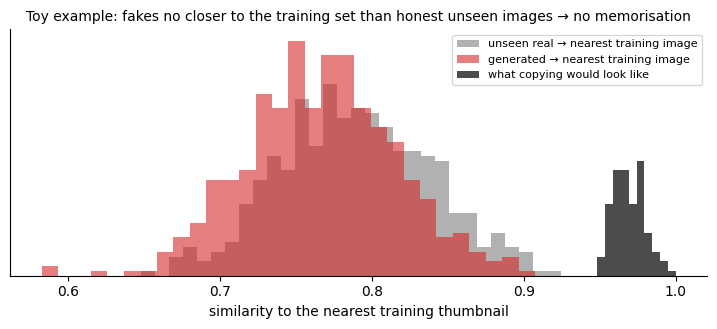

In [ ]:
train_ref = rng.choice(len(X_train), min(6000, len(X_train)), replace=False)
feat_ref = inception_features(X_train[torch.from_numpy(train_ref)])
ref_n = feat_ref / np.linalg.norm(feat_ref, axis=1, keepdims=True)


def nearest(feats):
    s = (feats / np.linalg.norm(feats, axis=1, keepdims=True)) @ ref_n.T
    return s.max(axis=1), s.argmax(axis=1)


sim_gen, nn_gen = nearest(feat_gen)
sim_hold, _ = nearest(feat_hold)
memo = pd.DataFrame({'generated': pd.Series(sim_gen).describe(), 'held-out real': pd.Series(sim_hold).describe()})

closest = np.argsort(-sim_gen)[:8]
fig, axes = plt.subplots(2, 8, figsize=(24, 4))
for k, g in enumerate(closest):
    axes[0, k].imshow(to_display(gen_imgs[g:g + 1])[0])
    axes[0, k].set_title(f'generated, sim {sim_gen[g]:.2f}', fontsize=9)
    axes[1, k].imshow(to_display(X_train[train_ref[nn_gen[g]]:train_ref[nn_gen[g]] + 1])[0])
    axes[1, k].set_title('nearest training image', fontsize=9)
for ax in axes.ravel():
    ax.set(xticks=[], yticks=[])
fig.suptitle('The 8 generated thumbnails closest to a training image', fontsize=13)
fig.tight_layout()
save(fig, '06_nearest_neighbours')
plt.show()

In [ ]:
display(memo.loc[['mean', '50%', 'max']].round(3))

# [13/14] Walking through the latent space

**What I'm trying to do** → move step by step between two random noise vectors; a smooth morph means the GAN learned a continuous space, not a lookup table.

**Question:** What happens between two generated thumbnails?

**Answer:** Every walk morphs smoothly (sky → night, title blocks grow and move) with no jumps: G learned a continuous space, not a list of images.

**Slerp in one line** → walk along the arc between two noise vectors instead of the straight line, so every step still looks like typical noise.

$$\text{slerp}(z_0, z_1; t) = \frac{\sin((1 - t)\,\Omega)}{\sin \Omega}\, z_0 + \frac{\sin(t\,\Omega)}{\sin \Omega}\, z_1, \qquad \cos \Omega = \frac{z_0 \cdot z_1}{\lVert z_0\rVert \lVert z_1\rVert}$$
- In short → the middle of a straight line is unusually short; G never saw noise like that

**How, in 3 steps**
1. Draw two random noise vectors $z_0$ and $z_1$
2. Make 8 in-between vectors along the arc ($t$ = 0 … 1)
3. Generate a thumbnail for each and show them in a row

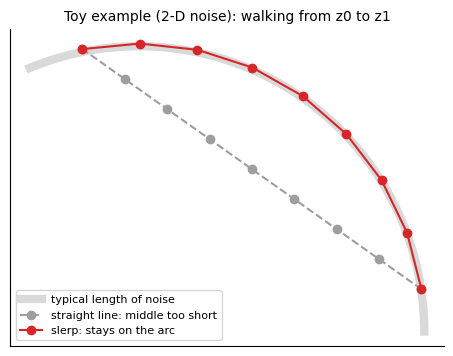

In [ ]:
def slerp(z0, z1, t):
    omega = torch.acos((z0 / z0.norm()) @ (z1 / z1.norm())).clamp(min=1e-6)
    return (torch.sin((1 - t) * omega) * z0 + torch.sin(t * omega) * z1) / torch.sin(omega)


rows = []
gen_z = torch.Generator(device='cpu').manual_seed(int(show_rng.integers(1_000_000)))
for _ in range(N_WALKS):
    z0, z1 = torch.randn(LATENT_DIM, generator=gen_z), torch.randn(LATENT_DIM, generator=gen_z)
    zs = torch.stack([slerp(z0, z1, t) for t in torch.linspace(0, 1, INTERP_STEPS)]).to(DEVICE)
    with torch.no_grad():
        rows.append(to_display(G(zs)))
fig, ax = plt.subplots(figsize=(20, 8))
ax.imshow(grid(np.concatenate(rows), ncols=INTERP_STEPS))
ax.set(title='Latent space walks: each row morphs from one generated thumbnail to another', xticks=[], yticks=[])
save(fig, '07_latent_walk')
plt.show()

# [14/14] Summary

- **Input → output** → 128 random numbers → one 64 × 128 thumbnail (unconditional, not text- or image-to-image)
- **Model** → upsample-conv G (3.7 M) vs spectral-norm D (2.8 M), hinge loss, EMA; 100 epochs ≈ 17 min on an RTX 5060
- **Quality** → FID 101–122 (plain DCGAN 227); no memorisation
- **Next** → genre-conditioned GAN using the recommender's clusters; larger images